<a href="https://colab.research.google.com/github/Ometh-cmd/taller-pandas-olimpiadas-grupoX/blob/faltantes-y-nuevas-variables/faltantes_y_nuevas_variables.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
athlete_events = pd.read_csv("Datos/athlete_events.csv")
noc_regions = pd.read_csv("Datos/noc_regions.csv")

# 3.5) Limpieza de datos

In [ ]:
import math
import matplotlib.pyplot as plt
import numpy as np
# Número de bins a utilizar en el histograma.
n = len(athlete_events.ID)
k = 1 + math.log(n, 2)
print (k)

19.04855073124767


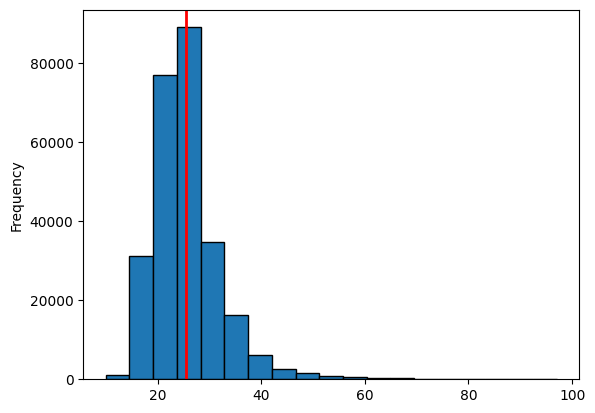

In [ ]:
# Age
athlete_events['Age'].plot(kind="hist", bins=19, edgecolor="black")
plt.axvline(np.mean(athlete_events.Age), color="red", linewidth=2)

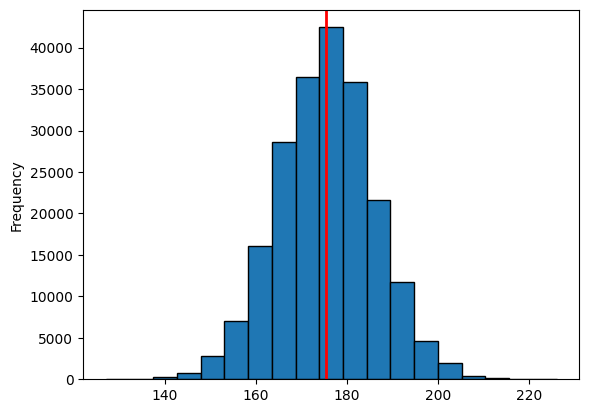

In [ ]:
# Height
athlete_events['Height'].plot(kind="hist", bins=19, edgecolor="black")
plt.axvline(np.mean(athlete_events.Height), color="red", linewidth=2)

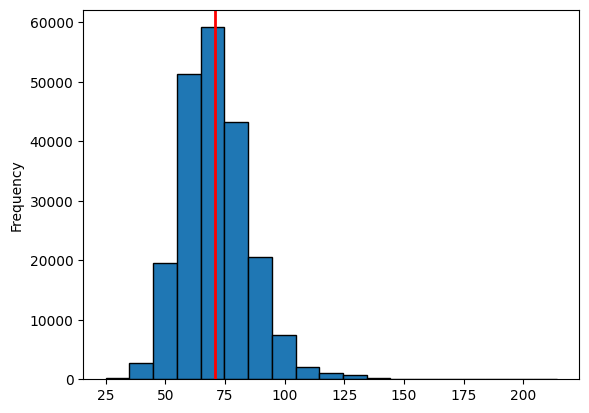

In [ ]:
# Weight
athlete_events['Weight'].plot(kind="hist", bins=19, edgecolor="black")
plt.axvline(np.mean(athlete_events.Weight), color="red", linewidth=2)

#4)
###Nueva variable IMC

In [ ]:
athlete_events['IMC'] = athlete_events['Weight'] / (athlete_events['Height']/100) ** 2

#5)
Fusionar lo datasets

In [ ]:
fusionado = athlete_events.merge(noc_regions, how='left', on='NOC')

Se utilizó 'left' para que se prioricen los datos de althete_events unidos con los de noc_regions y mezclandolos a partir de la variable NOC por eso se usa on= 'NOC'


In [ ]:
#display(athlete_events)
#display(fusionado)

#6)
###Nueva variable medalla

In [ ]:
# Recalculamos la columna binaria 'medalla' con los nuevos datos correctivos
fusionado['medalla'] = fusionado['Medal'].isin(['Gold', 'Silver', 'Bronze']).astype(int)


# 7)

In [ ]:
print(min(fusionado["Year"]))
print(max(fusionado["Year"]))

# Epoca
epoca = fusionado.groupby("Year").size()
epoca.plot(marker="o")

# Temporada
tempo = fusionado.groupby("Season").size()
tempo.plot.bar()
display(tempo)

# Sexo
sexo = fusionado.groupby("Sex").size()
sexo.plot.bar()
display(sexo)

1896
2016


#8)


In [ ]:
nulos_globales = fusionado.isnull().sum()
columnas_con_nulos = nulos_globales[nulos_globales > 0].index
display(fusionado[columnas_con_nulos].isnull().sum())

,0
Medal,231333
region,370
notes,266077


In [ ]:
fusionado['Era'] = fusionado['Year'].apply(lambda y: 'Antes de 1960' if y < 1960 else 'Después de 1960')

columnas_con_nulos = fusionado.columns[fusionado.isnull().any()]

comparacion_eras = fusionado.groupby('Era')[columnas_con_nulos].apply(lambda x: (x.isnull().mean() * 100))
display(comparacion_eras)

fusionado.drop(columns=['Era'], inplace=True)

,Medal,region,notes
Era,,,
Antes de 1960,81.653343,0.099929,98.069112
Después de 1960,86.416163,0.147318,98.162834
